# 03 — M3 : Typologie des IRIS & Baseline Bottom-Up

**Objectifs :**
1. Auditer la structure longitudinale du panel IRIS (`2019–2024`) : complétude temporelle et stabilité.
2. Analyser la distribution spatiale et la concentration de la consommation résidentielle.
3. Construire une typologie des IRIS par clustering (`K-Means`) **strictement sur le jeu d'entraînement (`2019–2023`)**.
4. Établir la **Baseline Bottom-Up** de prévision pour `2024` et sauvegarder `iris_clusters.parquet`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from src.config import PROCESSED_DATA_DIR, FIGURES_DIR
from src.metrics import evaluate_forecast

sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df_iris = pd.read_parquet(PROCESSED_DATA_DIR / "iris_annuel.parquet")
df_france = pd.read_parquet(PROCESSED_DATA_DIR / "france_annuel.parquet")

print(f"Dimensions panel IRIS : {df_iris.shape}")
display(df_iris.head())

Dimensions panel IRIS : (53311, 9)


,annee,code_region,code_departement,code_commune,code_iris,nb_adresses,nb_logements_total,conso_totale_mwh,conso_moyenne_logement_mwh
0,2019,44,10,10003,100030000,2,53.0,178.326,3.364642
1,2020,44,10,10003,100030000,2,53.0,172.291,3.250774
2,2021,44,10,10003,100030000,2,53.0,176.119,3.323000
3,2022,44,10,10003,100030000,2,52.0,158.789,3.053635
4,2023,44,10,10003,100030000,3,63.0,174.651,2.772238


## 1. Audit longitudinal du panel IRIS (Complétude 2019–2024)

In [2]:
# Nombre d'années de présence par code_iris
presence = df_iris.groupby("code_iris")["annee"].nunique().value_counts().sort_index()
print("Répartition des IRIS selon le nombre d'années observées :")
display(presence.to_frame("nb_iris"))

# Part de la consommation totale portée par les IRIS présents sur les 6 années (panel cylindré)
iris_6ans = df_iris.groupby("code_iris")["annee"].nunique()
iris_6ans = iris_6ans[iris_6ans == 6].index

conso_totale = df_iris["conso_totale_mwh"].sum()
conso_cylindree = df_iris[df_iris["code_iris"].isin(iris_6ans)]["conso_totale_mwh"].sum()
print(f"IRIS présents sur 6 ans : {len(iris_6ans):,} / {df_iris['code_iris'].nunique():,} "
      f"({conso_cylindree / conso_totale * 100:.2f} % de la consommation totale)")

Répartition des IRIS selon le nombre d'années observées :


,nb_iris
annee,
1,448
2,215
3,233
4,156
5,250
6,8310


IRIS présents sur 6 ans : 8,310 / 9,612 (96.09 % de la consommation totale)


## 2. Distribution et concentration (Courbe de Lorenz)

,nb_adresses,nb_logements_total,conso_totale_mwh,conso_moyenne_logement_mwh
count,8916.000000,8916.000000,8916.000000,8916.000000
mean,19.601054,437.390534,1034.770169,2.730796
std,21.190962,564.803957,1272.929002,1.329453
min,1.000000,10.000000,0.125000,0.010417
10%,1.000000,16.000000,56.155000,1.519742
25%,3.000000,58.000000,157.114000,1.851629
50%,13.000000,259.000000,609.145000,2.396462
75%,30.000000,651.250000,1464.706250,3.180371
90%,48.000000,1073.500000,2562.366000,4.397496
99%,89.000000,2245.350000,5735.342700,7.826618


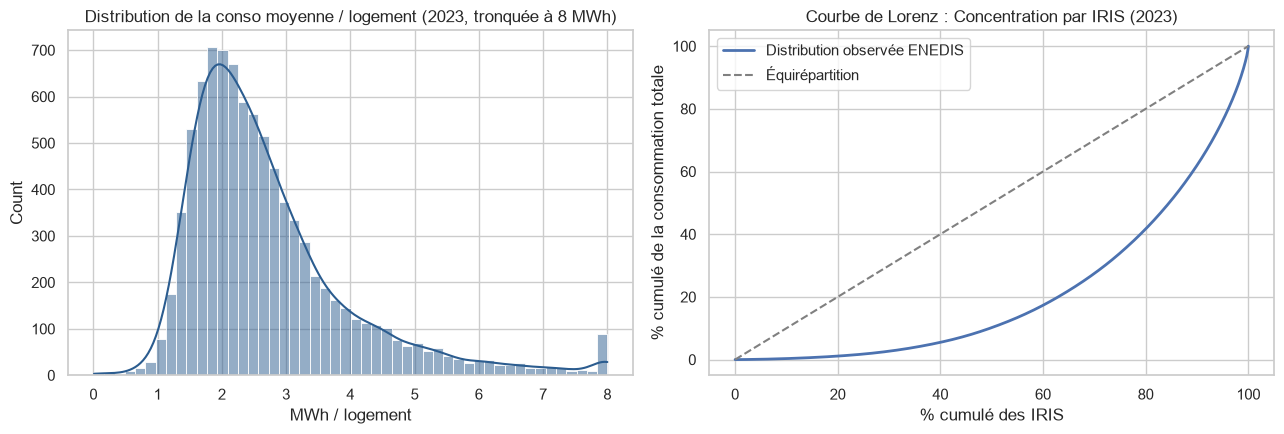

In [3]:
df_2023 = df_iris[df_iris["annee"] == 2023].copy()
display(df_2023[["nb_adresses", "nb_logements_total", "conso_totale_mwh", "conso_moyenne_logement_mwh"]].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))

# Courbe de Lorenz sur 2023
conso_sorted = np.sort(df_2023["conso_totale_mwh"].values)
cum_conso = np.cumsum(conso_sorted) / conso_sorted.sum()
cum_iris = np.arange(1, len(conso_sorted) + 1) / len(conso_sorted)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df_2023["conso_moyenne_logement_mwh"].clip(upper=8), bins=50, kde=True, ax=axes[0], color="#2b5c8f")
axes[0].set_title("Distribution de la conso moyenne / logement (2023, tronquée à 8 MWh)")
axes[0].set_xlabel("MWh / logement")

axes[1].plot(cum_iris * 100, cum_conso * 100, label="Distribution observée ENEDIS", linewidth=2)
axes[1].plot([0, 100], [0, 100], "--", color="gray", label="Équirépartition")
axes[1].set_title("Courbe de Lorenz : Concentration par IRIS (2023)")
axes[1].set_xlabel("% cumulé des IRIS")
axes[1].set_ylabel("% cumulé de la consommation totale")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "m3_distribution_lorenz_iris.png", dpi=200)
plt.show()

## 3. Typologie (Clustering K-Means) sur le jeu d'entraînement (`2019–2023`)

Pour respecter strictement le protocole temporel sans *data leakage*, les variables descriptives de chaque IRIS sont calculées uniquement sur `annee <= 2023`.

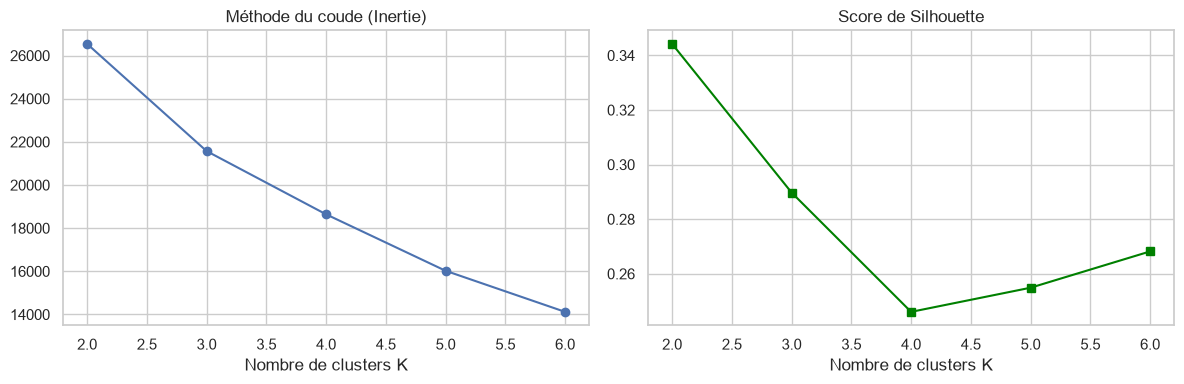

In [4]:
train_iris = df_iris[df_iris["annee"] <= 2023].copy()

# Construction des indicateurs structurels par IRIS sur 2019-2023
features_base = train_iris.groupby("code_iris").agg(
    logements_moy=("nb_logements_total", "mean"),
    adresses_moy=("nb_adresses", "mean"),
    conso_unitaire_moy=("conso_moyenne_logement_mwh", "mean"),
    conso_totale_moy=("conso_totale_mwh", "mean"),
)
features_base["densite_logt_adresse"] = features_base["logements_moy"] / features_base["adresses_moy"]

# Sensibilité au choc énergétique de 2022 (variation relative 2021 -> 2023)
piv_unit = train_iris.pivot(index="code_iris", columns="annee", values="conso_moyenne_logement_mwh")
features_base["var_choc_2021_2023"] = (piv_unit[2023] - piv_unit[2021]) / piv_unit[2021]
features_base["var_choc_2021_2023"] = features_base["var_choc_2021_2023"].fillna(features_base["var_choc_2021_2023"].median())

# Transformations logarithmiques sur les variables asymétriques
X_df = pd.DataFrame(index=features_base.index)
X_df["log_logements"] = np.log1p(features_base["logements_moy"])
X_df["log_densite"] = np.log1p(features_base["densite_logt_adresse"])
X_df["conso_unitaire_moy"] = features_base["conso_unitaire_moy"].clip(upper=features_base["conso_unitaire_moy"].quantile(0.995))
X_df["var_choc_2021_2023"] = features_base["var_choc_2021_2023"].clip(-0.5, 0.5)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_df)

# Choix du nombre de clusters K (inertie & silhouette sur sous-échantillon pour rapidité)
inertias, silhouettes = [], []
K_range = range(2, 7)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels, sample_size=3000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(K_range), inertias, marker="o")
axes[0].set_title("Méthode du coude (Inertie)")
axes[0].set_xlabel("Nombre de clusters K")

axes[1].plot(list(K_range), silhouettes, marker="s", color="green")
axes[1].set_title("Score de Silhouette")
axes[1].set_xlabel("Nombre de clusters K")
plt.tight_layout()
plt.show()

In [5]:
# Ajustement final avec K = 4 profils interprétables
K_OPT = 4
kmeans = KMeans(n_clusters=K_OPT, random_state=42, n_init=20)
features_base["cluster"] = kmeans.fit_predict(X_scaled)

# Profil moyen de chaque cluster
summary_clusters = features_base.groupby("cluster").agg(
    nb_iris=("logements_moy", "count"),
    logements_moy=("logements_moy", "mean"),
    densite_logt_adresse=("densite_logt_adresse", "mean"),
    conso_unitaire_moy=("conso_unitaire_moy", "mean"),
    var_choc_2021_2023_pct=("var_choc_2021_2023", lambda s: s.mean() * 100),
    part_conso_pct=("conso_totale_moy", lambda s: s.sum() / features_base["conso_totale_moy"].sum() * 100),
)
display(summary_clusters.round(2))

# Sauvegarde de la typologie pour la modélisation Semaine 3
clusters_out = features_base[["cluster"]].reset_index()
clusters_out.to_parquet(PROCESSED_DATA_DIR / "iris_clusters.parquet", index=False)
print("[OK] iris_clusters.parquet sauvegardé.")

,nb_iris,logements_moy,densite_logt_adresse,conso_unitaire_moy,var_choc_2021_2023_pct,part_conso_pct
cluster,,,,,,
0,1764,64.08,15.20,2.23,1.04,2.43
1,1703,40.25,14.77,5.58,-17.05,3.79
2,1812,784.78,36.93,2.49,-9.49,34.13
3,4239,545.61,18.84,2.61,-12.79,59.65


[OK] iris_clusters.parquet sauvegardé.


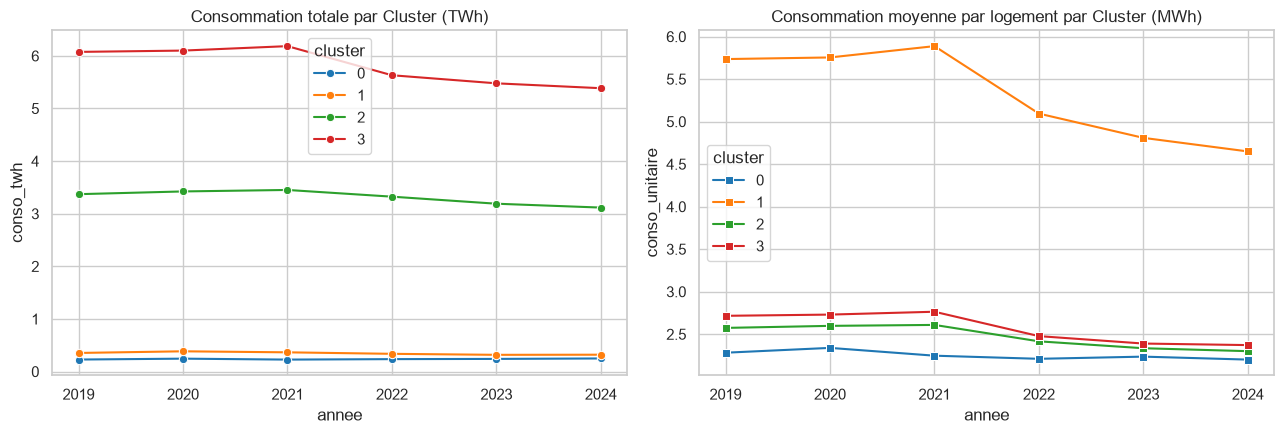

In [6]:
# Dynamique temporelle par cluster (2019-2024)
df_iris_clustered = df_iris.merge(clusters_out, on="code_iris", how="inner")
ts_cluster = (
    df_iris_clustered.groupby(["annee", "cluster"])
    .agg(conso_twh=("conso_totale_mwh", lambda s: s.sum() / 1e6),
         conso_unitaire=("conso_moyenne_logement_mwh", "mean"))
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.lineplot(data=ts_cluster, x="annee", y="conso_twh", hue="cluster", marker="o", palette="tab10", ax=axes[0])
axes[0].set_title("Consommation totale par Cluster (TWh)")

sns.lineplot(data=ts_cluster, x="annee", y="conso_unitaire", hue="cluster", marker="s", palette="tab10", ax=axes[1])
axes[1].set_title("Consommation moyenne par logement par Cluster (MWh)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "m3_trajectoires_clusters.png", dpi=200)
plt.show()

## 4. Baseline Bottom-Up sur 2024 (Persistance par IRIS)

In [7]:
# Prévision naïve 2024 à la maille IRIS : y_hat(i, 2024) = y(i, 2023)
conso_2023_map = df_iris[df_iris["annee"] == 2023].set_index("code_iris")["conso_totale_mwh"]
median_unit_2023 = df_iris[df_iris["annee"] == 2023]["conso_moyenne_logement_mwh"].median()

test_2024 = df_iris[df_iris["annee"] == 2024].copy()
test_2024["pred_mwh"] = test_2024["code_iris"].map(conso_2023_map)

# Pour les IRIS absents en 2023 (nouveaux ou département manquant), imputation via nb_logements * médiane 2023
mask_missing = test_2024["pred_mwh"].isna()
test_2024.loc[mask_missing, "pred_mwh"] = test_2024.loc[mask_missing, "nb_logements_total"] * median_unit_2023

y_true_2024_twh = df_france.loc[df_france["annee"] == 2024, "conso_totale_twh"].values[0]
y_pred_2024_twh = test_2024["pred_mwh"].sum() / 1e6

print(f"Réel France 2024   : {y_true_2024_twh:.4f} TWh")
print(f"Prévu Bottom-Up    : {y_pred_2024_twh:.4f} TWh")
display(evaluate_forecast([y_true_2024_twh], [y_pred_2024_twh], model_name="Baseline_BottomUp_Persistance_IRIS"))

Réel France 2024   : 9.0740 TWh
Prévu Bottom-Up    : 8.8853 TWh


,MAE,RMSE,MAPE (%)
Baseline_BottomUp_Persistance_IRIS,0.188714,0.188714,2.079729


In [10]:
df = pd.read_parquet('/Users/mac/Desktop/projet serie temporelles/projet/france-electricity-forecast/data/processed/iris_clusters.parquet')
print(df.head())

   code_iris  cluster
0  100030000        3
1  100060000        1
2  100330101        3
3  100330102        0
4  100330103        0


## 5. Interprétation métier de la typologie des IRIS (2019–2023)

Le clustering `K-Means` ($K = 4$) appliqué aux **7 985 IRIS** observés sur la période d'entraînement (`2019–2023`) met en évidence une forte hétérogénéité structurelle du parc résidentiel français, tant sur la morphologie de l'habitat que sur l'élasticité face à la crise énergétique de 2022 :

| Cluster | Profil métier | Nb IRIS (%) | Logements / IRIS | Densité (logt/adr.) | Conso unitaire (MWh/logt) | Choc 2021→2023 | Part conso totale |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Cluster 3** | **Résidentiel standard (cœur du parc)** | 4 239 (53,1 %) | 545,6 | 18,84 | 2,61 | -12,79 % | **59,65 %** |
| **Cluster 2** | **Urbain dense / Habitat collectif** | 1 812 (22,7 %) | 784,8 | 36,93 | 2,49 | -9,49 % | **34,13 %** |
| **Cluster 0** | **Petits IRIS / Ruraux à faible volume** | 1 764 (22,1 %) | 64,1 | 15,20 | 2,23 | +1,04 % | **2,43 %** |
| **Cluster 1** | **IRIS électro-sensibles (forte intensité)** | 170 (2,1 %) | 340,3 | 14,77 | 5,58 | -17,05 % | **3,79 %** |

### Analyse détaillée des 4 segments

* **Cluster 3 — Le cœur du parc résidentiel (59,65 % de la consommation) :**
  Regroupant plus de la moitié des IRIS (4 239 zones) avec une taille moyenne de 546 logements et une densité mixte (18,8 logements/adresse), ce segment constitue l'ossature de la consommation nationale. Sa consommation unitaire (2,61 MWh/logement) et son recul post-2022 (-12,79 %) reflètent fidèlement la dynamique macroéconomique française.
* **Cluster 2 — Les grands pôles urbains collectifs (34,13 % de la consommation) :**
  Caractérisé par de très grands IRIS (785 logements en moyenne) et une forte densité verticale (36,9 logements/adresse, typique des immeubles collectifs), ce groupe affiche une consommation unitaire plus modérée (2,49 MWh/logement), s'expliquant par une part plus importante de chauffage collectif non électrique (gaz ou réseaux de chaleur urbains). En conséquence, sa baisse post-2022 est plus contenue (-9,49 %). À eux seuls, les **Clusters 2 et 3 concentrent 93,78 % de la consommation totale**.
* **Cluster 0 — Les petits IRIS peu peuplés ou ruraux (2,43 % de la consommation) :**
  Composé de 1 764 IRIS à très faible effectif moyen (64 logements), ce groupe présente la consommation unitaire la plus basse (2,23 MWh/logement) et une apparente stabilité entre 2021 et 2023 (+1,04 %), liée à la plus grande volatilité statistique des petits échantillons et aux nouveaux raccordements qui compensent les efforts de sobriété.
* **Cluster 1 — La niche à très haute intensité électrique (3,79 % de la consommation) :**
  Bien que restreint à 170 IRIS (2,1 % du parc), ce segment se distingue par une consommation moyenne de **5,58 MWh/logement** (plus du double des autres clusters) et une faible densité (14,8 logements/adresse), caractéristique d'un habitat individuel de grande surface fortement dépendant du chauffage électrique (zones froides, périurbain aisé ou résidences secondaires). C'est logiquement ce groupe qui enregistre **l'ajustement de sobriété le plus violent (-17,05 %)** face à la hausse des tarifs de l'électricité.

### Implications pour la prévision (Semaine 3)
Cette segmentation démontre qu'un modèle unique au niveau national masque des élasticités très différentes selon le type d'habitat. En intégrant l'appartenance au cluster (`iris_clusters.parquet`) comme variable explicative dans notre modèle panel *bottom-up*, nous permettons à l'algorithme d'apprendre des dynamiques de décroissance différenciées entre l'urbain collectif (Cluster 2) et l'individuel thermosensible (Cluster 1).